# IND320 project work – Part 2

This notebook retrieves NVE reservoir data and ENTSO-E cross-border flows, processes the flow data with Spark/Cassandra, publishes curated data to MongoDB, and creates the required plots.

**Public links:**
https://github.com/M03ZGH/ind320-app

https://ind320-app-wktckrzn7uk2axexipgwwq.streamlit.app/


In [3]:
from pathlib import Path
import sys
import tomllib
import matplotlib.pyplot as plt
import pandas as pd

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "src" / "ind320_app").exists():
    raise RuntimeError("Run this notebook from the ind320-app project folder.")
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from ind320_app.data import load_reservoir_data, fetch_entsoe_flows, clean_flow_data, annual_energy_by_direction, utc_now

with (PROJECT_ROOT / ".streamlit" / "secrets.toml").open("rb") as file:
    secrets = tomllib.load(file)
print("Python:", sys.executable)


Python: /Users/moezyadgar/GitHub/IND320/ind320-app/.venv/bin/python


## 1. NVE API and reservoir plots

The Part 1 CSV is not used. The API response is normalized by the shared module used by the Streamlit app.

Rows: 14,931
Area types: ['EL', 'NO', 'VASS']


,date,area_type,area_number,year,week,filling_degree,capacity_TWh,filled_TWh,next_publication_date,filling_degree_previous_week,change_filling_degree
0,1995-01-08,EL,2,1995,1,0.630947,34.043590,21.479713,NaT,0.777604,-0.146657
1,1995-01-08,EL,3,1995,1,0.602376,8.920932,5.373754,NaT,0.596027,0.006349
2,1995-01-08,EL,4,1995,1,0.558864,21.079208,11.780413,NaT,0.801348,-0.242484
3,1995-01-08,NO,0,1995,1,0.607988,87.437580,53.161003,NaT,0.752631,-0.144643
4,1995-01-08,EL,1,1995,1,0.617574,6.003264,3.707457,NaT,0.583705,0.033869


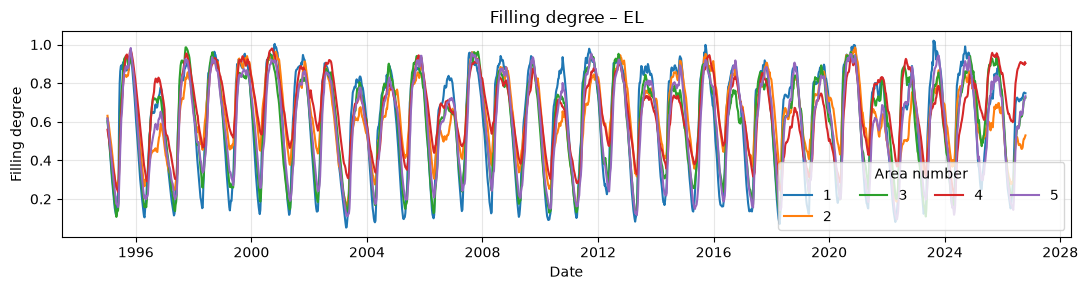

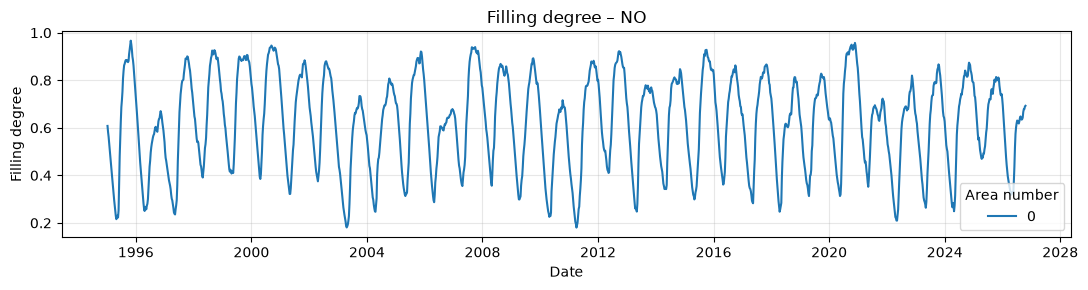

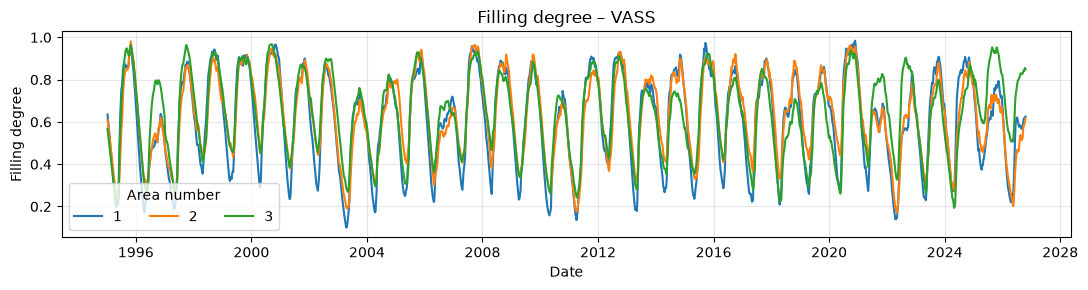

In [4]:
reservoirs_df = load_reservoir_data()
print("Rows:", f"{len(reservoirs_df):,}")
print("Area types:", sorted(reservoirs_df["area_type"].dropna().unique()))
display(reservoirs_df.head())

for area_type in ["EL", "NO", "VASS"]:
    area_data = reservoirs_df[reservoirs_df["area_type"] == area_type]
    figure, axis = plt.subplots(figsize=(11, 3))
    for area_number, group in area_data.groupby("area_number"):
        axis.plot(group["date"], group["filling_degree"], label=str(area_number))
    axis.set_title(f"Filling degree – {area_type}")
    axis.set_xlabel("Date")
    axis.set_ylabel("Filling degree")
    axis.grid(True, alpha=0.3)
    axis.legend(title="Area number", ncol=4)
    figure.tight_layout()
    plt.show()

# Capacity is retained as a data column, but not plotted as a time series because it is mostly constant.


## 2. ENTSO-E: last two years

The token is read from local secrets and never printed. Requests are split into one-year windows and both directions are labelled from Norway's perspective. `EL`, `NO` and `VASS` belong to the separate NVE reservoir dataset; they are not ENTSO-E bidding zones.

These are the transfers from/to Norway:
NO1 -> SE3,
SE3 -> NO1,
NO2 -> DE-LU,
DE-LU -> NO2,
NO2 -> DK1,
DK1 -> NO2,
NO2 -> GB,
GB -> NO2,
NO2 -> NL,
NL -> NO2,
NO3 -> SE2,
SE2 -> NO3,
NO4 -> FI,
FI -> NO4,
NO4 -> SE1,
SE1 -> NO4,
NO4 -> SE2,
SE2 -> NO4

In [5]:
from entsoe import EntsoePandasClient

from ind320_app.data import fetch_entsoe_flows

token = secrets.get("entsoe", {}).get("token", "")
if not token:
    raise ValueError("Add entsoe.token to .streamlit/secrets.toml.")
client = EntsoePandasClient(api_key=token)
# Bound each HTTP request so a stalled ENTSO-E endpoint cannot hang the run.
client.timeout = 30
end = utc_now()
start = end - pd.DateOffset(years=2)
print("ENTSO-E period:", start, "to", end)
connections = [
    ("NO_1", "SE_3", "NO_1-SE_3"),
    ("NO_2", "DK_1", "NO_2-DK_1"),
    ("NO_2", "GB", "NO_2-GB"),
    ("NO_4", "SE_2", "NO_4-SE_2"),
]
flows_df = fetch_entsoe_flows(client, connections, start, end, max_workers=4)
print("Flow observations:", f"{len(flows_df):,}")
print("Flow date range:", flows_df["timestamp"].min(), "to", flows_df["timestamp"].max())


ENTSO-E period: 2024-10-22 22:00:00+00:00 to 2026-10-22 22:00:00+00:00
Completed ENTSO-E request 1/16
Completed ENTSO-E request 2/16
Completed ENTSO-E request 3/16
Completed ENTSO-E request 4/16
Completed ENTSO-E request 5/16
Completed ENTSO-E request 6/16
Completed ENTSO-E request 7/16
Completed ENTSO-E request 8/16
Completed ENTSO-E request 9/16
Completed ENTSO-E request 10/16
Completed ENTSO-E request 11/16
Completed ENTSO-E request 12/16
Completed ENTSO-E request 13/16
Completed ENTSO-E request 14/16
Completed ENTSO-E request 15/16
Completed ENTSO-E request 16/16
Flow observations: 438,348
Flow date range: 2024-10-22 22:00:00+00:00 to 2026-10-22 21:45:00+00:00


In [6]:
# Fresh API data is created in the previous cell. No backup data is used.
if "flows_df" not in globals() or flows_df.empty:
    raise ValueError("Fresh ENTSO-E data is not available.")
print("Using fresh ENTSO-E data:", f"{len(flows_df):,} observations")


Using fresh ENTSO-E data: 438,348 observations


## 3. Spark and Cassandra

Start Cassandra locally before running this cell. The keyspace and table are created explicitly so a fresh local installation does not fail at the Spark write.

In [7]:
from cassandra.cluster import Cluster
from pyspark.sql import SparkSession, functions as F

cassandra = Cluster(["127.0.0.1"], port=9042)
cassandra_session = cassandra.connect()
cassandra_session.execute("CREATE KEYSPACE IF NOT EXISTS ind320 WITH replication = {'class': 'SimpleStrategy', 'replication_factor': 1}")
cassandra_session.execute("CREATE TABLE IF NOT EXISTS ind320.crossborder_flows (connection text, direction text, timestamp timestamp, flow_mw double, source_zone text, target_zone text, PRIMARY KEY ((connection, direction), timestamp))")

spark = (SparkSession.builder.appName("IND320-Part2")
    .config("spark.jars.packages", "com.datastax.spark:spark-cassandra-connector_2.12:3.5.1")
    .config("spark.cassandra.connection.host", "127.0.0.1")
    .getOrCreate())
spark.sparkContext.setLogLevel("WARN")
cassandra_columns = ["connection", "direction", "timestamp", "flow_mw", "source_zone", "target_zone"]
spark_flows = spark.createDataFrame(flows_df).select(*cassandra_columns)
cassandra_session.execute("TRUNCATE ind320.crossborder_flows")
spark_flows.write.format("org.apache.spark.sql.cassandra").options(keyspace="ind320", table="crossborder_flows").mode("append").save()
clean_spark = (spark.read.format("org.apache.spark.sql.cassandra").options(keyspace="ind320", table="crossborder_flows").load().withColumn("year", F.year("timestamp")).withColumn("month", F.month("timestamp")))
clean_spark.show(5, truncate=False)


26/10/23 00:42:06 WARN Utils: Your hostname, Moez-sin-MacBook-Pro.local resolves to a loopback address: 127.0.0.1; using 192.168.11.187 instead (on interface en0)
26/10/23 00:42:06 WARN Utils: Set SPARK_LOCAL_IP if you need to bind to another address
Ivy Default Cache set to: /Users/moezyadgar/.ivy2/cache
The jars for the packages stored in: /Users/moezyadgar/.ivy2/jars
com.datastax.spark#spark-cassandra-connector_2.12 added as a dependency
:: resolving dependencies :: org.apache.spark#spark-submit-parent-c59d508f-b0c7-449b-9b0f-c79eea8bda1a;1.0
	confs: [default]


:: loading settings :: url = jar:file:/Users/moezyadgar/GitHub/IND320/ind320-app/.venv/lib/python3.12/site-packages/pyspark/jars/ivy-2.5.1.jar!/org/apache/ivy/core/settings/ivysettings.xml


	found com.datastax.spark#spark-cassandra-connector_2.12;3.5.1 in central
	found com.datastax.spark#spark-cassandra-connector-driver_2.12;3.5.1 in central
	found org.scala-lang.modules#scala-collection-compat_2.12;2.11.0 in central
	found org.apache.cassandra#java-driver-core-shaded;4.18.1 in central
	found com.datastax.oss#native-protocol;1.5.1 in central
	found com.datastax.oss#java-driver-shaded-guava;25.1-jre-graal-sub-1 in central
	found com.typesafe#config;1.4.1 in central
	found org.slf4j#slf4j-api;1.7.26 in central
	found io.dropwizard.metrics#metrics-core;4.1.18 in central
	found org.hdrhistogram#HdrHistogram;2.1.12 in central
	found org.reactivestreams#reactive-streams;1.0.3 in central
	found org.apache.cassandra#java-driver-mapper-runtime;4.18.1 in central
	found org.apache.cassandra#java-driver-query-builder;4.18.1 in central
	found org.apache.commons#commons-lang3;3.10 in central
	found com.thoughtworks.paranamer#paranamer;2.8 in central
	found org.scala-lang#scala-reflect

+----------+------------+-------------------+-------+-----------+-----------+----+-----+
|connection|direction   |timestamp          |flow_mw|source_zone|target_zone|year|month|
+----------+------------+-------------------+-------+-----------+-----------+----+-----+
|NO_2-DK_1 |import_to_NO|2024-10-23 00:00:00|0.0    |DK_1       |NO_2       |2024|10   |
|NO_2-DK_1 |import_to_NO|2024-10-23 01:00:00|0.0    |DK_1       |NO_2       |2024|10   |
|NO_2-DK_1 |import_to_NO|2024-10-23 02:00:00|0.0    |DK_1       |NO_2       |2024|10   |
|NO_2-DK_1 |import_to_NO|2024-10-23 03:00:00|0.0    |DK_1       |NO_2       |2024|10   |
|NO_2-DK_1 |import_to_NO|2024-10-23 04:00:00|0.0    |DK_1       |NO_2       |2024|10   |
+----------+------------+-------------------+-------+-----------+-----------+----+-----+
only showing top 5 rows



## 4. Required plots and MongoDB publication

This section uses the fresh ENTSO-E data loaded directly from the API above. Requests are bounded and run concurrently to avoid the long sequential execution from the earlier attempt. A chosen connection is selected from the available connections for the notebook demonstration. The annual pie chart shows estimated energy in the two directions for the selected year, while the line chart shows both directions during January with a readable UTC date axis.

MongoDB publication is enabled below. Records are upserted using connection, direction and timestamp as the key. The writes are split into batches and a unique index is created so rerunning this cell is safe and does not create duplicate observations.

The Streamlit application reads the curated records from the MongoDB collection.

Using chosen connection: NO_1-SE_3; year: 2026


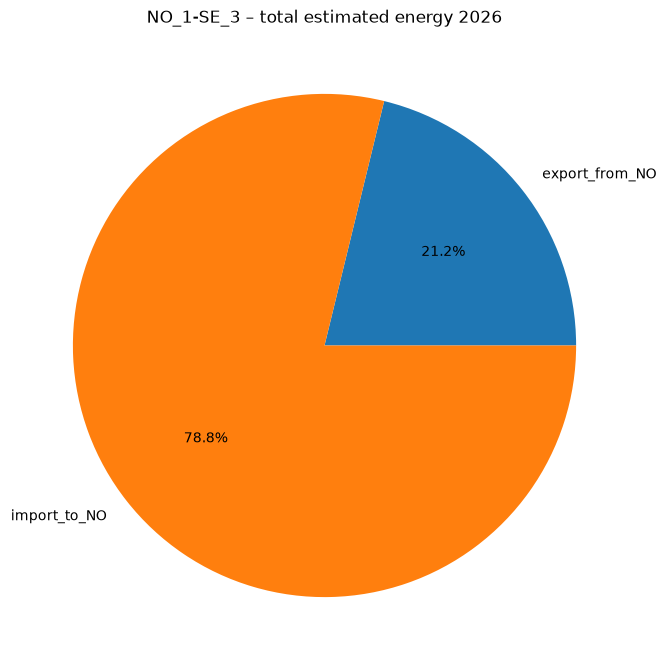

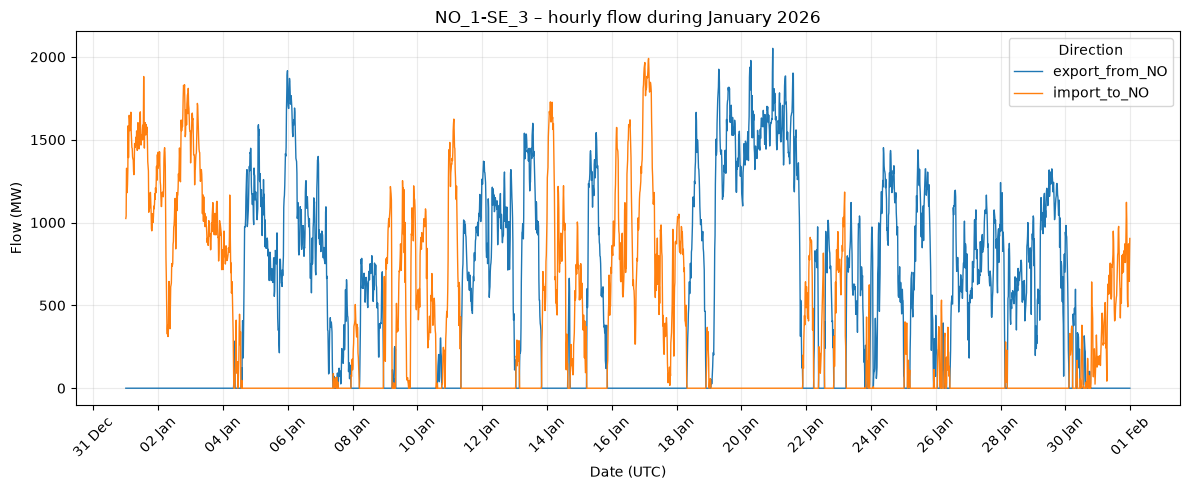

MongoDB upserts completed: 50,000/438,348
MongoDB upserts completed: 100,000/438,348
MongoDB upserts completed: 150,000/438,348
MongoDB upserts completed: 200,000/438,348
MongoDB upserts completed: 250,000/438,348
MongoDB upserts completed: 300,000/438,348
MongoDB upserts completed: 350,000/438,348
MongoDB upserts completed: 400,000/438,348
MongoDB upserts completed: 438,348


In [8]:
from matplotlib.dates import DateFormatter, DayLocator
from pymongo import MongoClient, UpdateOne

# Use the first available connection as the notebook example. The Streamlit app lets the user choose one.
plot_df = clean_flow_data(flows_df)
connection = sorted(plot_df["connection"].unique())[0]
year = int(plot_df.loc[plot_df["connection"] == connection, "year"].max())
print(f"Using chosen connection: {connection}; year: {year}")

# Required plot 1: annual energy split by direction.
annual = annual_energy_by_direction(plot_df, connection, year)
fig, ax = plt.subplots(figsize=(7, 7))
annual.plot.pie(
    y="energy_mwh",
    labels=annual["direction"],
    autopct="%.1f%%",
    legend=False,
    ax=ax,
    title=f"{connection} – total estimated energy {year}",
)
ax.set_ylabel("")
fig.tight_layout()
plt.show()

# Required plot 2: separate lines for each direction during January.
january = plot_df[
    (plot_df["connection"] == connection)
    & (plot_df["year"] == year)
    & (plot_df["month"] == 1)
].sort_values("timestamp")
fig, ax = plt.subplots(figsize=(12, 5))
for direction, group in january.groupby("direction"):
    ax.plot(group["timestamp"], group["flow_mw"], linewidth=1, label=direction)
ax.set_title(f"{connection} – hourly flow during January {year}")
ax.set_xlabel("Date (UTC)")
ax.set_ylabel("Flow (MW)")
ax.xaxis.set_major_locator(DayLocator(interval=2))
ax.xaxis.set_major_formatter(DateFormatter("%d %b"))
ax.tick_params(axis="x", rotation=45)
ax.grid(True, alpha=0.25)
ax.legend(title="Direction")
fig.tight_layout()
plt.show()

PUBLISH_TO_MONGODB = True
if not PUBLISH_TO_MONGODB:
    print("MongoDB upload skipped for the time-limited run; set PUBLISH_TO_MONGODB = True when ready.")

if PUBLISH_TO_MONGODB:
    mongo_uri = secrets.get("mongo", {}).get("uri", "")
    if not mongo_uri:
        raise ValueError("Add mongo.uri to .streamlit/secrets.toml.")
    mongo_client = MongoClient(
        mongo_uri,
        serverSelectionTimeoutMS=10000,
        connectTimeoutMS=10000,
        maxPoolSize=5,
        minPoolSize=0,
        maxIdleTimeMS=60000,
        waitQueueTimeoutMS=30000,
    )
    mongo_client.admin.command("ping")
    collection = mongo_client["ind320"]["crossborder_flows"]
    collection.create_index(
        [("connection", 1), ("direction", 1), ("timestamp", 1)],
        unique=True,
    )

    batch_size = 1000
    operations = []
    written = 0
    for record in plot_df.to_dict("records"):
        record["timestamp"] = pd.Timestamp(record["timestamp"]).to_pydatetime()
        key = {name: record[name] for name in ("connection", "direction", "timestamp")}
        operations.append(UpdateOne(key, {"$set": record}, upsert=True))
        if len(operations) >= batch_size:
            collection.bulk_write(operations, ordered=False)
            written += len(operations)
            operations = []
            if written % 50000 == 0:
                print(f"MongoDB upserts completed: {written:,}/{len(plot_df):,}")
    if operations:
        collection.bulk_write(operations, ordered=False)
        written += len(operations)
    print(f"MongoDB upserts completed: {written:,}")


In [9]:
print(collection.count_documents({}))
print(sorted(collection.distinct("connection")))
print(sorted(collection.distinct("direction")))

438507
['NO_1-SE_3', 'NO_2-DK_1', 'NO_2-GB', 'NO_4-SE_2']
['export_from_NO', 'import_to_NO']


## 5. Log and AI usage (300–500 words)

During Part 2 I replaced the reservoir CSV workflow with a direct connection to the NVE Magasinstatistikk API. I inspected the returned columns, converted date fields to pandas datetimes and checked the available EL, NO and VASS area types. The reservoir plots were recreated from the live response, and the same loader is used by Streamlit.

I worked with the ENTSO-E Transparency Platform API by selecting four Norwegian interconnections and requesting the previous two years in one-year windows. The requests run with bounded concurrency to avoid a long sequential wait. Both directions were labelled as export from Norway or import to Norway. The data was converted to UTC timestamps and duplicate observations were removed. One hourly MW observation is treated as one MWh in the required annual estimate, and this assumption is documented in the app.

Spark was used to create a DataFrame and write observations to Cassandra. I read the data back, selected the relevant columns and added year and month fields. The curated result was published to MongoDB with upserts, making reruns safe and giving the Streamlit app a database designed for online reads.

The Streamlit experience showed me the difference between notebook exploration and an application. I added an API-backed reservoir page with an interval slider and radio buttons for area type. A separate page reads MongoDB and uses two columns: the left side contains the yearly connection pie chart, while the right side contains a multi-month line plot. The source explanation is placed in an expander.

AI tools were used to understand error messages, check API usage, discuss the data pipeline and improve Python and Streamlit structure. I reviewed and adapted all suggestions and tested the resulting code. Secrets remain in local Streamlit configuration and are excluded from GitHub.